In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)


In [2]:
import os

zip_path = r"C:\Users\shivam shilpkar\Downloads\IDC409_Project_raw_data.zip"

print("File exists:", os.path.exists(zip_path))

File exists: True


In [3]:
import os
import pandas as pd

for root, dirs, files in os.walk("student_data"):
    for file in files:
        if file == "student-mat.csv":
            csv_path = os.path.join(root, file)

df = pd.read_csv(csv_path, sep=";")

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [5]:
# Select the input variables and target variable

X = df[
    ["G1", "G2", "failures", "Medu", "Fedu", "studytime"]
]

y = df["G3"]

print("Input data:")
print(X.head())

print("\nTarget (final grades):")
print(y.head())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input data:
   G1  G2  failures  Medu  Fedu  studytime
0   5   6         0     4     4          2
1   5   5         0     1     1          2
2   7   8         3     1     1          2
3  15  14         0     4     2          3
4   6  10         0     3     3          2

Target (final grades):
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

Input shape: (395, 6)
Target shape: (395,)


In [6]:
# Create the classification target: 1 = Pass, 0 = Fail
df['result'] = (df['G3'] >= 10).astype(int)

print(df[['G3', 'result']].head())
print('\nClass counts (0 = Fail, 1 = Pass):')
print(df['result'].value_counts().sort_index())

   G3  result
0   6       0
1   6       0
2  10       1
3  15       1
4  10       1

Class counts (0 = Fail, 1 = Pass):
result
0    130
1    265
Name: count, dtype: int64


In [7]:
X = df[['studytime', 'absences', 'G1', 'G2']]
y = df['result']

print('Input features:', X.columns.tolist())
print('Number of examples:', len(y))


Input features: ['studytime', 'absences', 'G1', 'G2']
Number of examples: 395


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=62,
    stratify=y
)

print('Training examples:', len(y_train))
print('Testing examples:', len(y_test))


Training examples: 316
Testing examples: 79


In [9]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print('Baseline accuracy:', accuracy_score(y_test, baseline_predictions))


Baseline accuracy: 0.6708860759493671


In [10]:
# max_depth limits the tree size and can help reduce overfitting
classifier = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=62
)

classifier.fit(X_train, y_train)
print('Decision Tree model trained successfully.')


Decision Tree model trained successfully.


In [11]:
predictions = classifier.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

print(f'Accuracy  = {accuracy:.3f}')
print(f'Precision = {precision:.3f}')
print(f'Recall    = {recall:.3f}')
print(f'F1-score  = {f1:.3f}')

print('\nClassification report:')
print(classification_report(
    y_test, predictions,
    labels=[0, 1],
    target_names=['Fail', 'Pass'],
    zero_division=0
))


Accuracy  = 0.873
Precision = 0.957
Recall    = 0.849
F1-score  = 0.900

Classification report:
              precision    recall  f1-score   support

        Fail       0.75      0.92      0.83        26
        Pass       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79



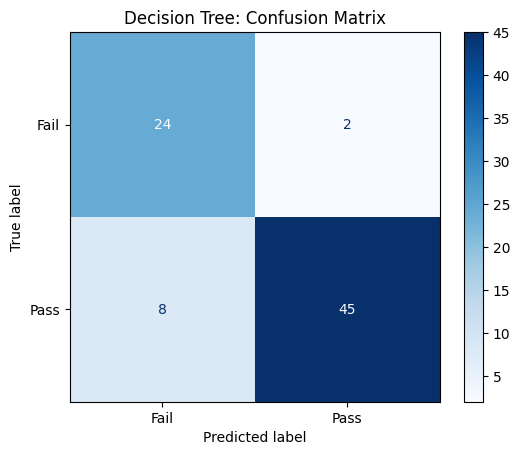

In [12]:
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)
display.plot(cmap='Blues')
plt.title('Decision Tree: Confusion Matrix')
plt.show()


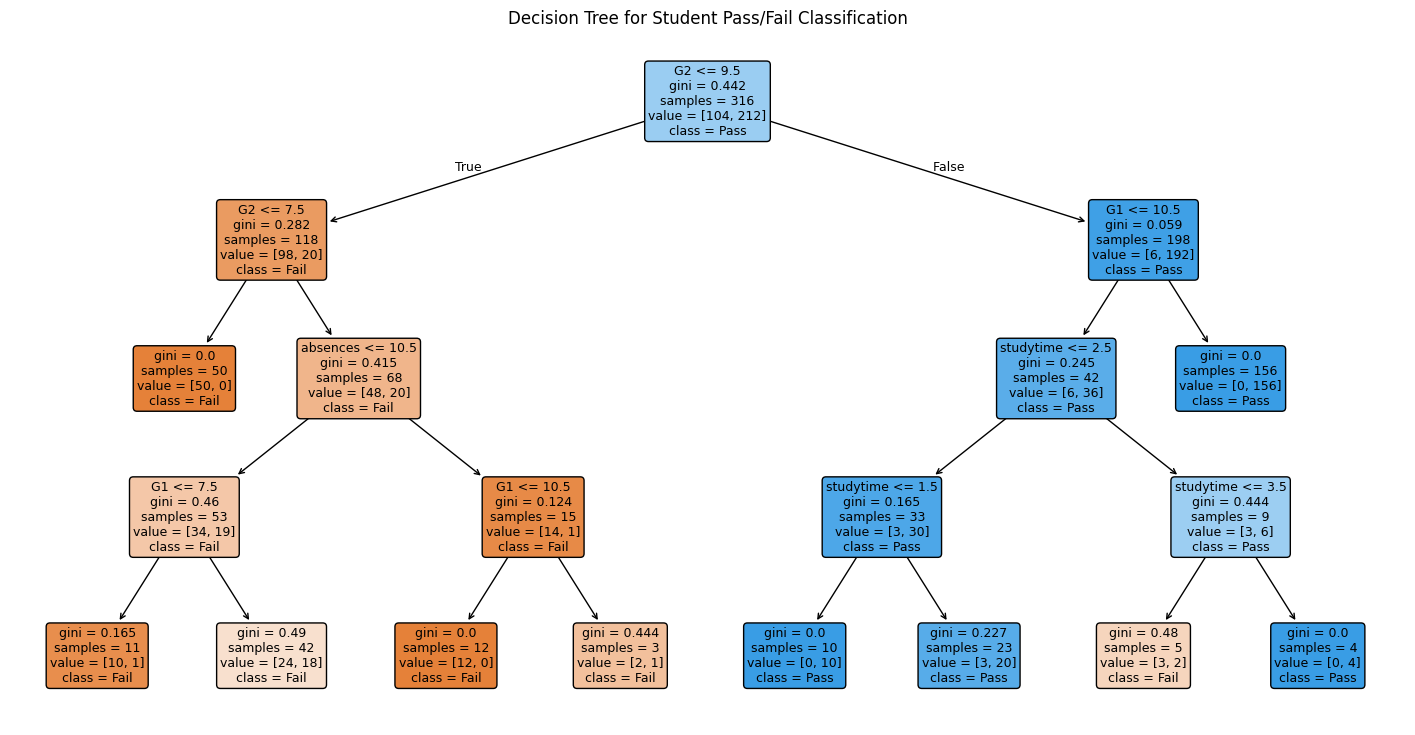

In [13]:
plt.figure(figsize=(18, 9))
plot_tree(
    classifier,
    feature_names=X.columns,
    class_names=['Fail', 'Pass'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree for Student Pass/Fail Classification')
plt.show()


G2           0.921155
G1           0.035782
studytime    0.024660
absences     0.018403
dtype: float64


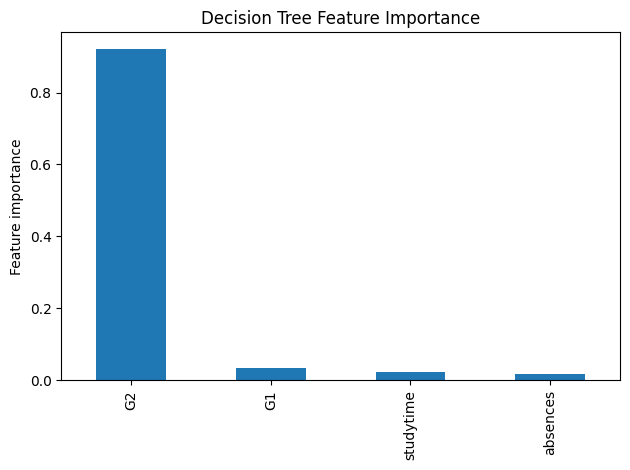

In [14]:
importance = pd.Series(
    classifier.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)
importance.plot(kind='bar')
plt.ylabel('Feature importance')
plt.title('Decision Tree Feature Importance')
plt.tight_layout()
plt.show()
